In [ ]:

# Install KaggleHub if needed
import kagglehub
import os
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml

# Download the dataset
path = kagglehub.dataset_download(
    "ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes"
)

# Display the dataset location
print("Dataset downloaded successfully!")
print("Path to dataset files:", path)

# Display the main folders and files
print("\nDataset contents:")

for item in os.listdir(path):
    item_path = os.path.join(path, item)

    if os.path.isdir(item_path):
        print(f"📁 {item}/")
    else:
        print(f"📄 {item}")

print("ziko ziko ziko")

Dataset downloaded successfully!
Path to dataset files: /home/mrcyber/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/1

Dataset contents:
📁 Val/
📁 Train/


In [85]:
# EDA :

# check extensions : 

valid_extensions = ["jpeg", "jpg", "bmp", "png"]

for folder_name in os.listdir(os.path.join(path , "Train")) : 
    
    for image_path in os.listdir(os.path.join(path , "Train" , folder_name , "images")) : 
        
        image_extension = image_path.split(".")[1]
        
        try : 
        
            if image_extension not  in valid_extensions : 
                
                raise ValueError(f"This Extension cant be valid {image_extension}")
        
        except ValueError as err: 
            print(err)
            raise

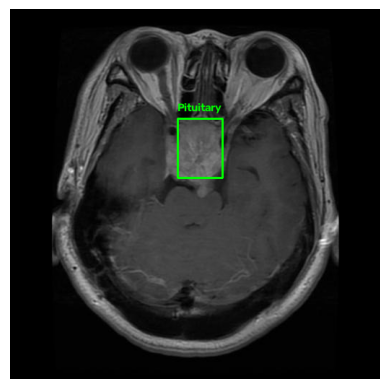

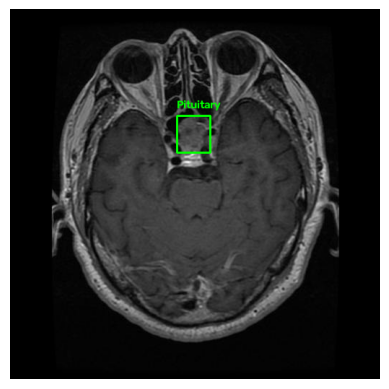

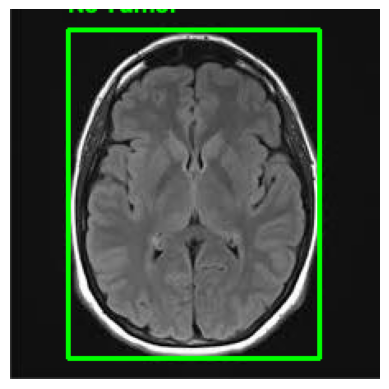

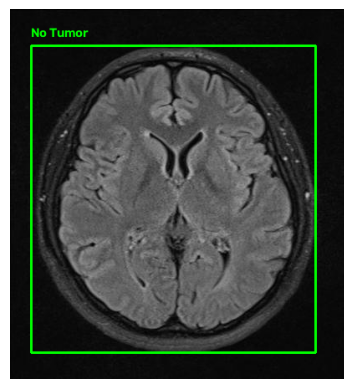

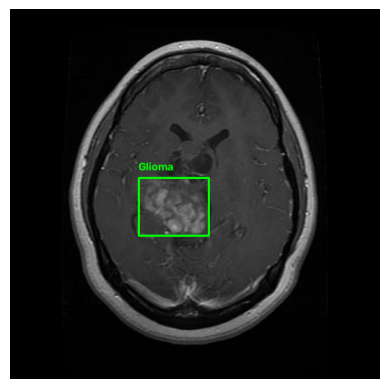

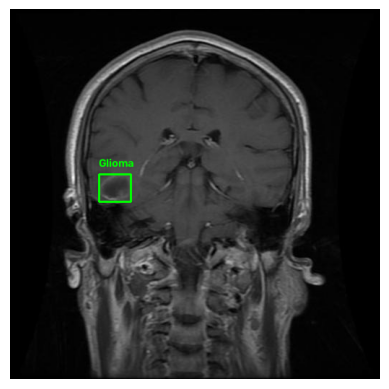

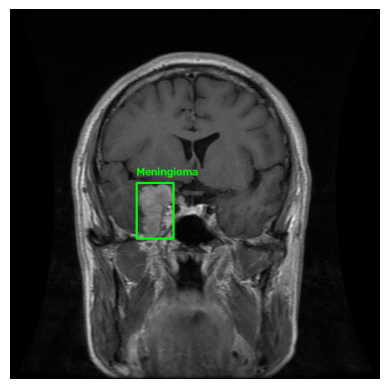

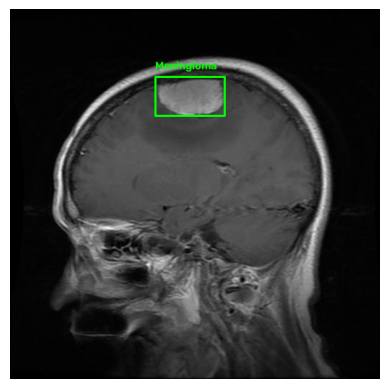

In [86]:
 

# display pics : 


classes = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}
path_to_images = os.path.join(path , "Train")


for folder_name in os.listdir(path_to_images) : 
    
    folder_images = os.listdir(os.path.join(path_to_images , folder_name, "images"))
    folder_labels = os.listdir(os.path.join(path_to_images , folder_name , "labels"))
    i = 0 
    for image_name in folder_images :
        
        
        image_path = os.path.join(path_to_images , folder_name ,  "images" , image_name) 
        
        img = cv2.imread(image_path)
        
        height , width = img.shape[:2]
        
        
        label_name = os.path.splitext(image_name)[0] + ".txt"
        
        label_path = os.path.join(path_to_images, folder_name, "labels", label_name)
        
        with open(label_path, 'r') as file : 
            
            
            labels = file.readlines()
            
        
        for label in labels :     
        
            class_id, x_center, y_center, box_width, box_height = map(float, label.split())

       
            x_center = int(x_center * width)
            y_center = int(y_center * height)
     
            box_width = int(box_width * width)
            box_height = int(box_height * height)  
            
            
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
    
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)
            
            
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
            
            
            cv2.putText(
                img , 
                folder_name , 
                (x1, y1 -10), 
                cv2.FONT_HERSHEY_SIMPLEX, 
                0.5 , 
                (0,255,0), 
                2
            )
            
            
            plt.imshow(cv2.cvtColor(img , cv2.COLOR_BGR2RGB))
            plt.axis("off")
            plt.show()
            
            
            break
        i += 1
        if i == 2 : 
            break
        
        
    
    


In [87]:
# raise if there is a classes without label , except No Tumor 


path_to_images = os.path.join(path , "Train")


for folder_name in os.listdir(path_to_images) : 
    
    folder_images = os.listdir(os.path.join(path_to_images , folder_name, "images"))
    folder_labels = os.listdir(os.path.join(path_to_images , folder_name , "labels"))
   
    for image_name in folder_images :
        
        
        image_path = os.path.join(path_to_images , folder_name ,  "images" , image_name) 
        
        img = cv2.imread(image_path)
        
        height , width = img.shape[:2]
        
        
        label_name = os.path.splitext(image_name)[0] + ".txt"
        
        label_path = os.path.join(path_to_images, folder_name, "labels", label_name)
        
        with open(label_path, 'r') as file : 
            
            
            labels = file.readlines()
            try : 
                if not labels and folder_name != "No Tumor" : 
                    raise ValueError("There is No label ")
              
            except ValueError as err : 
                
                print(err)
                raise
        
        

In [88]:
# calculate number of images in each folder in Train and Val : 

result = {}

path_to_images = os.path.join(path , "Train")

for big_folder in os.listdir(os.path.join(path)) : 
    if big_folder not in result : 
        result[big_folder] =  {}
        
    for folder_name in os.listdir(os.path.join(path , big_folder)) : 
    
        
        
        folder_images = os.listdir(os.path.join(path , big_folder , folder_name, "images"))
        
        if folder_name not in result[big_folder] : 
            
            result[big_folder][folder_name] = len(folder_images)

            
        
    
result

{'Val': {'Pituitary': 136, 'No Tumor': 100, 'Glioma': 136, 'Meningioma': 140},
 'Train': {'Pituitary': 1424,
  'No Tumor': 711,
  'Glioma': 1153,
  'Meningioma': 1449}}

In [89]:
# processing : 


# get images  . 

images = []
labels = []


for folder_name in os.listdir(path_to_images) : 
    
    folder_images = os.listdir(os.path.join(path_to_images , folder_name, "images"))
    folder_labels = os.listdir(os.path.join(path_to_images , folder_name , "labels"))
   
    for image_name in folder_images :
        
        
        image_path = os.path.join(path_to_images , folder_name ,  "images" , image_name) 
        
        img = cv2.imread(image_path)
       





In [90]:
import shutil
from pathlib import Path

# ================== CONFIG ==================
SOURCE_DIR = Path(path)          # ← put your real path here
OUTPUT_DIR = Path("../data")
CLASSES = ["Glioma", "Meningioma", "NoTumor", "Pituitary"]
# ============================================

# Create folders
for split in ["train", "val"]:
    (OUTPUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

def process_split(source_split: str, target_split: str):
    count = 0
    print(f"\n--- Processing {source_split} → {target_split} ---")

    for class_name in CLASSES:
        img_dir = SOURCE_DIR / source_split / class_name / "images"
        lbl_dir = SOURCE_DIR / source_split / class_name / "labels"

        if not img_dir.exists():
            print(f"Missing: {img_dir}")
            continue

        for img_path in img_dir.glob("*"):
            if img_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                continue

            # ===== Get the EXACT original name =====
            original_name = img_path.name          # full name with extension
            original_stem = img_path.stem          # name without extension

            # Destination paths (using exact original name)
            dest_img = OUTPUT_DIR / "images" / target_split / original_name
            dest_lbl = OUTPUT_DIR / "labels" / target_split / f"{original_stem}.txt"

            # Copy image
            #shutil.copy2(img_path, dest_img)
            img = cv2.imread(str(img_path))

            # Resize to 640 × 640
            img_resized = cv2.resize(img, (640, 640))
            
            # Save the resized image
            cv2.imwrite(str(dest_img), img_resized)

            # Copy label if exists
            src_lbl = lbl_dir / f"{original_stem}.txt"
            if src_lbl.exists():
                shutil.copy2(src_lbl, dest_lbl)
                count += 1
                # Print to confirm name is the same
                print(f"Copied: {original_name}")
            else:
                print(f"Missing label for: {original_name}")

    print(f"✅ Total copied in {target_split}: {count}")

# ================== RUN ==================
print("Starting conversion...")
process_split("Train", "train")
process_split("Val", "val")

# Create data.yaml
yaml_content = f"""path: {OUTPUT_DIR.resolve()}
train: images/train
val: images/val

names:
  0: Glioma
  1: Meningioma
  2: NoTumor
  3: Pituitary
"""
(OUTPUT_DIR / "data.yaml").write_text(yaml_content)

print(f"\n🎉 Finished! Check the folder: {OUTPUT_DIR.resolve()}")

Starting conversion...

--- Processing Train → train ---
Copied: Tr-gl_0380.jpg
Copied: gg (706).jpg
Copied: Te-gl_0272.jpg
Copied: gg (40).jpg
Copied: Tr-gl_1039.jpg
Copied: gg (213).jpg
Copied: Tr-gl_0916.jpg
Copied: Tr-gl_0946.jpg
Copied: Tr-gl_0201.jpg
Copied: gg (598).jpg
Copied: gg (272).jpg
Copied: gg (269).jpg
Copied: Tr-gl_0040.jpg
Copied: gg (275).jpg
Copied: gg (740).jpg
Copied: gg (822).jpg
Copied: Tr-glTr_0000.jpg
Copied: gg (155).jpg
Copied: Te-gl_0015.jpg
Copied: Tr-gl_0115.jpg
Copied: Tr-gl_0548.jpg
Copied: Tr-gl_1280.jpg
Copied: gg (69).jpg
Copied: Tr-gl_1137.jpg
Copied: gg (499).jpg
Copied: gg (61).jpg
Copied: Tr-gl_0486.jpg
Copied: gg (559).jpg
Copied: gg (166).jpg
Copied: gg (651).jpg
Copied: gg (123).jpg
Copied: Tr-gl_1103.jpg
Copied: gg (192).jpg
Copied: gg (477).jpg
Copied: Tr-gl_0649.jpg
Copied: Tr-gl_0638.jpg
Copied: gg (199).jpg
Copied: Te-gl_0063.jpg
Copied: Tr-gl_0917.jpg
Copied: gg (763).jpg
Copied: gg (134).jpg
Copied: gg (285).jpg
Copied: gg (547).jpg
Cop

In [ ]:
# importing the model : 
from ultralytics import YOLO
import ultralytics
model = YOLO("yolov8n.pt")


8.4.189


In [83]:
import albumentations as A
custom_augmentations = [
    A.RandomBrightnessContrast(
        brightness_limit=0.15,
        contrast_limit=0.15,
        p=0.3
    )
]
result = model.train(
    data="../data/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8  ,
    
    # Geometric augmentations
    degrees=5.0,
    scale=0.2,
    translate=0.05,

    # Brightness and color
    hsv_v=0.2,
    hsv_h=0.0,
    hsv_s=0.0,

    # Flips and Mosaic
    fliplr=0.0,
    flipud=0.0,
    mosaic=0.0,

    # Custom brightness and contrast
    augmentations=custom_augmentations
)

ModuleNotFoundError: No module named 'albumentations'